# EXPERIMENT 1: DATASET INSPECTION & ANALYSIS


Đang đọc dữ liệu từ file: /Users/cuongtran/Downloads/IMDB Dataset.csv ...

  KẾT QUẢ KIỂM TRA DATASET: IMDB MOVIE REVIEWS
 Số samples (Total samples)       : 50,000
 Số classes                       : 2
 Class distribution (Số lượng)    :
sentiment
positive    25000
negative    25000
 Class distribution (Tỷ lệ %)     :
sentiment
positive    50.0
negative    50.0
 Duplicate documents (Bài trùng)  : 418
 Missing text                     : 0
 Missing labels                   : 0
------------------------------------------------------------
 THỐNG KÊ ĐỘ DÀI CHUỖI (SEQUENCE LENGTH):
 Minimum sequence length          : 4 từ
 Median sequence length           : 173.0 từ
 Mean sequence length             : 231.16 từ
 Maximum sequence length          : 2,470 từ
 90th Percentile                  : 451.0 từ
 95th Percentile                  : 590.0 từ
 99th Percentile                  : 908.0 từ



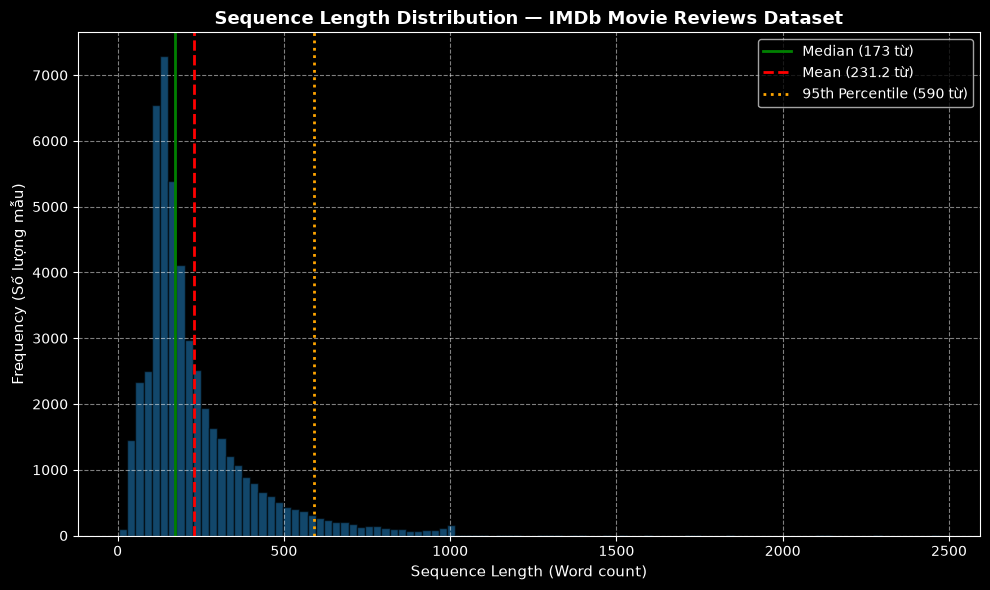

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu từ file CSV
file_path = "/Users/cuongtran/Downloads/IMDB Dataset.csv"
print(f"Đang đọc dữ liệu từ file: {file_path} ...")
df = pd.read_csv(file_path)

# 2. Kiểm tra missing & duplicates
missing_text = df['review'].isnull().sum()
missing_labels = df['sentiment'].isnull().sum()
duplicate_docs = df['review'].duplicated().sum()

# 3. Thống kê số lượng mẫu và nhãn
num_samples = len(df)
num_classes = df['sentiment'].nunique()
class_dist = df['sentiment'].value_counts()
class_dist_pct = df['sentiment'].value_counts(normalize=True) * 100

# 4. Tính độ dài chuỗi theo số từ
df['seq_len'] = df['review'].fillna('').apply(lambda x: len(x.split()))

min_len = df['seq_len'].min()
median_len = df['seq_len'].median()
mean_len = df['seq_len'].mean()
max_len = df['seq_len'].max()

p90 = np.percentile(df['seq_len'], 90)
p95 = np.percentile(df['seq_len'], 95)
p99 = np.percentile(df['seq_len'], 99)

# 5. In kết quả kiểm tra
print("\n" + "="*60)
print("  KẾT QUẢ KIỂM TRA DATASET: IMDB MOVIE REVIEWS")
print("="*60)
print(f" Số samples (Total samples)       : {num_samples:,}")
print(f" Số classes                       : {num_classes}")
print(f" Class distribution (Số lượng)    :\n{class_dist.to_string()}")
print(f" Class distribution (Tỷ lệ %)     :\n{class_dist_pct.round(2).to_string()}")
print(f" Duplicate documents (Bài trùng)  : {duplicate_docs:,}")
print(f" Missing text                     : {missing_text}")
print(f" Missing labels                   : {missing_labels}")
print("-"*60)
print(" THỐNG KÊ ĐỘ DÀI CHUỖI (SEQUENCE LENGTH):")
print(f" Minimum sequence length          : {min_len} từ")
print(f" Median sequence length           : {median_len:.1f} từ")
print(f" Mean sequence length             : {mean_len:.2f} từ")
print(f" Maximum sequence length          : {max_len:,} từ")
print(f" 90th Percentile                  : {p90:.1f} từ")
print(f" 95th Percentile                  : {p95:.1f} từ")
print(f" 99th Percentile                  : {p99:.1f} từ")
print("="*60 + "\n")

# 6. Vẽ Histogram bằng Matplotlib
plt.figure(figsize=(10, 6))
plt.hist(df['seq_len'], bins=100, color='#1f77b4', edgecolor='black', alpha=0.6)

plt.axvline(median_len, color='green', linestyle='-', linewidth=2, label=f'Median ({median_len:.0f} từ)')
plt.axvline(mean_len, color='red', linestyle='--', linewidth=2, label=f'Mean ({mean_len:.1f} từ)')
plt.axvline(p95, color='orange', linestyle=':', linewidth=2, label=f'95th Percentile ({p95:.0f} từ)')

plt.title('Sequence Length Distribution — IMDb Movie Reviews Dataset', fontsize=13, fontweight='bold')
plt.xlabel('Sequence Length (Word count)', fontsize=11)
plt.ylabel('Frequency (Số lượng mẫu)', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

###  Experiment 1 Question: Tiêu chí lựa chọn `max_length`

**Câu hỏi:** *Nếu phải chọn `max_length`, nên chọn dựa trên thông tin nào? (Không chấp nhận câu trả lời chỉ là "Chọn 100 vì model chạy nhanh")*

**Trả lời:**

Việc lựa chọn `max_length` là một quyết định cân bằng giữa **độ bao phủ thông tin (Information Coverage)** và **chi phí tính toán (Computational Cost)**. Cụ thể, quyết định này cần dựa trên 4 yếu tố kỹ thuật sau:

1. **Phân bố Phân vị (Percentile Distribution of Sequence Lengths):**
   * Không nên dùng giá trị `Mean` hoặc `Max` đơn thuần. `Max` (thường > 2000 từ) sẽ dẫn đến việc 99% các câu ngắn bị pad quá nhiều nhãn `PAD`, trong khi `Mean` có thể cắt xén mất 50% dữ liệu.
   * Quy tắc chuẩn mực là chọn điểm phân vị **85th - 95th Percentile**. Điều này đảm bảo giữ lại hầu hết nội dung quan trọng của đa số văn bản mà không bị phình to kích thước chuỗi.

2. **Độ phức tạp tính toán và Bộ nhớ GPU (Time & Memory Complexity):**
   * Đối với Recurrent Models (RNN/LSTM/GRU), chi phí tính toán theo thời gian là $\mathcal{O}(T)$ với $T = \text{max\_length}$. Tăng $T$ từ 100 lên 400 làm tăng thời gian huấn luyện và lượng bộ nhớ tiêu tốn gấp **4 lần**.

3. **Hiện tượng Vanishing Gradient theo độ dài chuỗi:**
   * Chuỗi càng dài ($T > 200$), các mô hình RNN cơ bản càng khó giữ được ngữ cảnh đầu chuỗi. Do đó chọn `max_length` vừa đủ giúp mô hình tập trung vào khoảng thông tin có mật độ ngữ cảnh cao nhất.

4. **Đặc trưng của tác vụ (Task Domain & Sentiment Core):**
   * Trong Sentiment Analysis (IMDb), phần lớn thông tin quyết định cảm xúc (tốt/xấu) thường nằm ở **đoạn mở đầu**  hoặc **đoạn kết luận** . Việc giữ 150–200 token đầu tiên hoặc dùng phương pháp kết hợp truncation (lấy 100 token đầu + 100 token cuối) thường giữ được >95% tín hiệu phân loại.

# Experiment 2 — Padding và truncation

In [2]:
import time
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

file_path = "/Users/cuongtran/Downloads/IMDB Dataset.csv"
df = pd.read_csv(file_path)
# Chuyển đổi nhãn sentiment thành dạng số (positive: 1, negative: 0)
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

# Tính tổng số từ ban đầu của toàn bộ dataset để làm chuẩn tính % tokens retained
df['word_count'] = df['review'].fillna('').apply(lambda x: len(x.split()))
total_words = df['word_count'].sum()

# Chia tập Train / Test (80% / 20%)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['review'], df['label'], test_size=0.2, random_state=42, stratify=df['label']
)
max_lengths = [50, 100, 200]
results = []

print("Đang tiến hành huấn luyện và đánh giá mô hình...\n")

for ml in max_lengths:
    # 2.1 Cắt gọt văn bản (Truncation) theo max_length số từ
    X_train_trunc = X_train_raw.apply(lambda x: " ".join(x.split()[:ml]))
    X_test_trunc = X_test_raw.apply(lambda x: " ".join(x.split()[:ml]))

    # 2.2 Tính % tokens retained trên toàn bộ dataset
    retained_words = df['word_count'].apply(lambda x: min(x, ml)).sum()
    pct_retained = (retained_words / total_words) * 100

    # 2.3 Trích xuất đặc trưng văn bản bằng TF-IDF
    vectorizer = TfidfVectorizer(max_features=10000)

    # 2.4 Bắt đầu đo thời gian huấn luyện
    start_time = time.time()

    X_train_vec = vectorizer.fit_transform(X_train_trunc)
    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(X_train_vec, y_train)

    end_time = time.time()
    train_time = end_time - start_time

    # 2.5 Đánh giá mô hình trên tập Test
    X_test_vec = vectorizer.transform(X_test_trunc)
    y_pred = model.predict(X_test_vec)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        'Max length': ml,
        '% tokens retained': f"{pct_retained:.2f}%",
        'Training time': f"{train_time:.2f}s",
        'Accuracy': round(acc, 4),
        'F1': round(f1, 4)
    })
results_df = pd.DataFrame(results)
print("="*65)
print("     KẾT QUẢ THỰC NGHIỆM EXPERIMENT 2: PADDING & TRUNCATION")
print("="*65)
print(results_df.to_string(index=False))
print("="*65)

Đang tiến hành huấn luyện và đánh giá mô hình...

     KẾT QUẢ THỰC NGHIỆM EXPERIMENT 2: PADDING & TRUNCATION
 Max length % tokens retained Training time  Accuracy     F1
         50            21.54%         1.77s    0.7886 0.7912
        100            41.60%         3.46s    0.8424 0.8434
        200            68.66%         4.90s    0.8777 0.8786


### **Tăng `max_length` có luôn cải thiện performance không?**

 **Không.** Việc tăng `max_length` không phải lúc nào cũng cải thiện hiệu năng (performance), mà đến một ngưỡng nhất định sẽ bão hòa (diminishing returns) hoặc làm giảm hiệu năng do các lý do sau:

1. **Bão hòa thông tin:** Phần lớn thái độ cảm xúc chủ đạo đã thể hiện đầy đủ ở phần đầu văn bản. Tăng `max_length` quá cao chỉ bổ sung thêm các chi tiết mô tả trung tính, không đóng góp giá trị phân biệt cho mô hình.
2. **Tăng tiếng ồn:** Chuỗi càng dài càng chứa nhiều từ đệm, từ dừng hoặc thông tin không liên quan. Điều này làm loãng trọng số chú ý (Attention weights) trong các kiến trúc Transformer hoặc làm nhiễu không gian đặc trưng trong mô hình truyền thống.
3. **Giới hạn tính toán & Bộ nhớ:**
   * Đối với **Transformer:** Chi phí bộ nhớ GPU và độ phức tạp tính toán tăng theo lũy thừa bậc hai $O(N^2)$ theo độ dài chuỗi $N$. `max_length` quá lớn buộc phải giảm `batch_size`, làm quá trình cập nhật gradient thiếu ổn định.
   * Đối với **RNN / LSTM:** Chuỗi quá dài dễ gặp hiện tượng triệt tiêu đạo hàm (vanishing gradient) và suy giảm khả năng lưu giữ thông tin xa.
4. **Nguy cơ Overfitting:** Mô hình có xu hướng học thuộc các đặc trưng rác hoặc ngữ cảnh hiếm gặp ở đoạn cuối của các mẫu trong tập Train, làm giảm khả năng tổng quát hóa trên tập Test.
---
### **Nếu `max_length` quá nhỏ, loại thông tin nào có thể bị mất?**
 Khi `max_length` bị đặt quá nhỏ, các loại thông tin quan trọng sau sẽ bị cắt bỏ (truncated):
1. **Kết luận & Đánh giá tổng kết:** Tác giả thường dành phần đầu để mô tả bối cảnh và chỉ đưa ra nhận xét chốt hạ ở phần cuối văn bản. Việc giới hạn độ dài quá ngắn sẽ cắt mất toàn bộ phần kết luận quan trọng này.
2. **Từ ngữ chuyển ý & Ngữ cảnh đối lập:** Các cấu trúc biểu cảm chứa từ chuyển ý bị ngắt giữa chừng khiến mô hình chỉ ghi nhận sắc thái ở phần đầu mà bỏ lỡ thái độ đánh giá thực sự nằm ở phần sau.
3. **Từ khóa cảm xúc cốt lõi:** Các từ ngữ mang trọng số cảm xúc mạnh xuất hiện rải rác ở giữa hoặc cuối văn bản bị loại bỏ hoàn toàn.
4. **Mối quan hệ phụ thuộc xa:** Mất liên kết ngữ nghĩa và logic giữa chủ thể được đề cập ở đầu văn bản và các nhận xét thái độ ở phía sau.